In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import interpolate
import pandas as pd

In [ ]:
df = pd.read_csv("DSC_table_Drp_05_Abs_025_Rcv_075_Wnd_20.csv")

for id_val in df['ID'].unique():
    data = df[df['ID'] == id_val]
    id_num = id_val.replace('ID_', '')
    
    globals()[f"DSC_lengths_{id_num}"] = data['DSC_lengths'].tolist()
    globals()[f"DSC_path_to_soma_{id_num}"] = data['DSC_path_to_soma'].tolist()
    globals()[f"DSC_diam_{id_num}"] = data['DSC_diam'].tolist()

In [11]:
# average +- std
print( list(df) )
print('DSC_lengths:', np.mean(df['DSC_lengths'] ) , np.std(df['DSC_lengths'] ) )
print('DSC_path_to_soma:', np.mean(df['DSC_path_to_soma'] ) , np.std(df['DSC_path_to_soma'] ))
print('DSC_diam:', np.mean(df['DSC_diam'] ) , np.std(df['DSC_diam'] ))
len(df)

['ID', 'DSC_lengths', 'DSC_path_to_soma', 'DSC_diam', 'coordinates_MICrONS']
DSC_lengths: 1.1849185257678105 0.3612919471892182
DSC_path_to_soma: 190.2537335349333 87.75546516108103
DSC_diam: 169.3252205882353 121.26052094583085


68

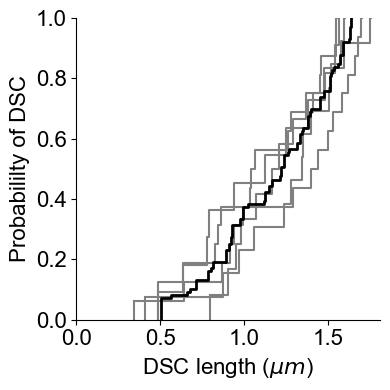

In [ ]:
n_bins=200
n1, bins1, patches = plt.hist(DSC_lengths_864691136194996812, n_bins, density=True, histtype='step', cumulative=True)
n2, bins2, patches = plt.hist(DSC_lengths_864691135374673737, n_bins, density=True, histtype='step', cumulative=True)
n3, bins3, patches = plt.hist(DSC_lengths_864691135693733567, n_bins, density=True, histtype='step', cumulative=True)
n4, bins4, patches = plt.hist(DSC_lengths_864691135738411121, n_bins, density=True, histtype='step', cumulative=True)
n5, bins5, patches = plt.hist(DSC_lengths_864691134884807418, n_bins, density=True, histtype='step', cumulative=True)
plt.close()

plt.figure(figsize=(4, 4))
plt.step(bins1[:-1], n1, color='gray')
plt.vlines(bins1[0], 0, n1[0], color='gray')
plt.step(bins2[:-1], n2, color='gray')
plt.vlines(bins2[0], 0, n2[0], color='gray')
plt.step(bins3[:-1], n3, color='gray')
plt.vlines(bins3[0], 0, n3[0], color='gray')
plt.step(bins4[:-1], n4, color='gray')
plt.vlines(bins4[0], 0, n4[0], color='gray')
plt.step(bins5[:-1], n5, color='gray')
plt.vlines(bins5[0], 0, n5[0], color='gray')

# Create a common set of probability points (y-values)
prob_points = np.linspace(0, 1, 100)

# Create interpolation functions for each CDF
f1 = interpolate.interp1d(n1, bins1[:-1], bounds_error=False, fill_value=(bins1[0], bins1[-2]))
f2 = interpolate.interp1d(n2, bins2[:-1], bounds_error=False, fill_value=(bins2[0], bins2[-2]))
f3 = interpolate.interp1d(n3, bins3[:-1], bounds_error=False, fill_value=(bins3[0], bins3[-2]))
f4 = interpolate.interp1d(n4, bins4[:-1], bounds_error=False, fill_value=(bins4[0], bins4[-2]))
f5 = interpolate.interp1d(n5, bins5[:-1], bounds_error=False, fill_value=(bins5[0], bins5[-2]))

# Calculate average x-values for each probability point
avg_x = np.zeros_like(prob_points)
for i, p in enumerate(prob_points):
    x_vals = [f1(p), f2(p), f3(p), f4(p), f5(p)]
    avg_x[i] = np.mean(x_vals)

# Plot the average CDF in black
plt.step(avg_x, prob_points, color='black', linewidth=2, label='Average')
plt.vlines(avg_x[0], 0, prob_points[0], color='black', linewidth=2)

plt.xlim([0,np.max(bins1)*1.15])
plt.ylim([0, 1])
plt.xlabel("DSC length ($\mu m$)", fontsize=16, family='Arial')
plt.ylabel("Probabililty of DSC", fontsize=16, family='Arial')

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.xticks(family='Arial'); plt.yticks(family='Arial')
plt.tick_params(axis="x", labelsize=16); plt.tick_params(axis="y", labelsize=16)
plt.tight_layout()

#plt.savefig("DSC_length_graph.pdf", bbox_inches='tight')
plt.show()

# 2. Distance of the DSC from the soma

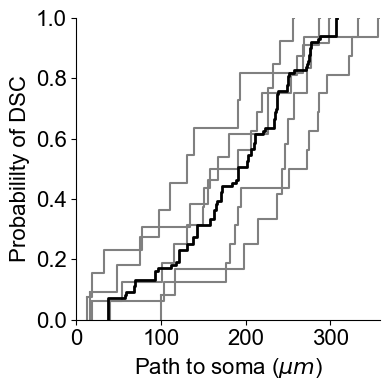

In [ ]:
n_bins=200
n1, bins1, patches = plt.hist(DSC_path_to_soma_864691136194996812, n_bins, density=True, histtype='step', cumulative=True)
n2, bins2, patches = plt.hist(DSC_path_to_soma_864691135374673737, n_bins, density=True, histtype='step', cumulative=True)
n3, bins3, patches = plt.hist(DSC_path_to_soma_864691135693733567, n_bins, density=True, histtype='step', cumulative=True)
n4, bins4, patches = plt.hist(DSC_path_to_soma_864691135738411121, n_bins, density=True, histtype='step', cumulative=True)
n5, bins5, patches = plt.hist(DSC_path_to_soma_864691134884807418, n_bins, density=True, histtype='step', cumulative=True)
plt.close()

plt.figure(figsize=(4, 4))
plt.step(bins1[:-1], n1, color='gray')
plt.vlines(bins1[0], 0, n1[0], color='gray')
plt.step(bins2[:-1], n2, color='gray')
plt.vlines(bins2[0], 0, n2[0], color='gray')
plt.step(bins3[:-1], n3, color='gray')
plt.vlines(bins3[0], 0, n3[0], color='gray')
plt.step(bins4[:-1], n4, color='gray')
plt.vlines(bins4[0], 0, n4[0], color='gray')
plt.step(bins5[:-1], n5, color='gray')
plt.vlines(bins5[0], 0, n5[0], color='gray')

prob_points = np.linspace(0, 1, 100)

# Create interpolation functions for each CDF
f1 = interpolate.interp1d(n1, bins1[:-1], bounds_error=False, fill_value=(bins1[0], bins1[-2]))
f2 = interpolate.interp1d(n2, bins2[:-1], bounds_error=False, fill_value=(bins2[0], bins2[-2]))
f3 = interpolate.interp1d(n3, bins3[:-1], bounds_error=False, fill_value=(bins3[0], bins3[-2]))
f4 = interpolate.interp1d(n4, bins4[:-1], bounds_error=False, fill_value=(bins4[0], bins4[-2]))
f5 = interpolate.interp1d(n5, bins5[:-1], bounds_error=False, fill_value=(bins5[0], bins5[-2]))

# Calculate average x-values for each probability point
avg_x = np.zeros_like(prob_points)
for i, p in enumerate(prob_points):
    x_vals = [f1(p), f2(p), f3(p), f4(p), f5(p)]
    avg_x[i] = np.mean(x_vals)

# Plot the average CDF in black
plt.step(avg_x, prob_points, color='black', linewidth=2, label='Average')
plt.vlines(avg_x[0], 0, prob_points[0], color='black', linewidth=2)

plt.xlim([0,np.max(bins1)*1.24])
plt.ylim([0, 1])
plt.xlabel("Path to soma ($\mu m$)", fontsize=16, family='Arial')
plt.ylabel("Probabililty of DSC", fontsize=16, family='Arial')

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.xticks(family='Arial'); plt.yticks(family='Arial')
plt.tick_params(axis="x", labelsize=16); plt.tick_params(axis="y", labelsize=16)
plt.tight_layout()

#plt.savefig("DSC_path_to_soma_graph.pdf", bbox_inches='tight')
plt.show()

# 3. DSC diameter

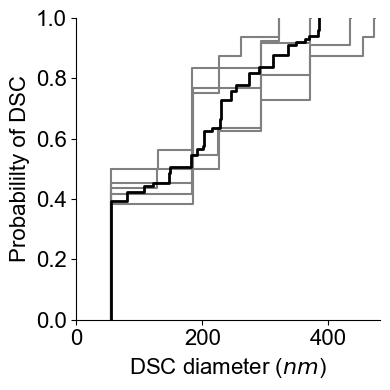

In [ ]:
n_bins = 200
n1, bins1, patches = plt.hist(DSC_diam_864691136194996812, n_bins, density=True, histtype='step', cumulative=True)
n2, bins2, patches = plt.hist(DSC_diam_864691135374673737, n_bins, density=True, histtype='step', cumulative=True)
n3, bins3, patches = plt.hist(DSC_diam_864691135693733567, n_bins, density=True, histtype='step', cumulative=True)
n4, bins4, patches = plt.hist(DSC_diam_864691135738411121, n_bins, density=True, histtype='step', cumulative=True)
n5, bins5, patches = plt.hist(DSC_diam_864691134884807418, n_bins, density=True, histtype='step', cumulative=True)
plt.close()

plt.figure(figsize=(4, 4))
plt.step(bins1[:-1], n1, color='gray')
plt.vlines(bins1[0], 0, n1[0], color='gray')
plt.step(bins2[:-1], n2, color='gray')
plt.vlines(bins2[0], 0, n2[0], color='gray')
plt.step(bins3[:-1], n3, color='gray')
plt.vlines(bins3[0], 0, n3[0], color='gray')
plt.step(bins4[:-1], n4, color='gray')
plt.vlines(bins4[0], 0, n4[0], color='gray')
plt.step(bins5[:-1], n5, color='gray')
plt.vlines(bins5[0], 0, n5[0], color='gray')

# Create a common set of probability points (y-values)
prob_points = np.linspace(0, 1, 100)

# Create interpolation functions for each CDF
f1 = interpolate.interp1d(n1, bins1[:-1], bounds_error=False, fill_value=(bins1[0], bins1[-2]))
f2 = interpolate.interp1d(n2, bins2[:-1], bounds_error=False, fill_value=(bins2[0], bins2[-2]))
f3 = interpolate.interp1d(n3, bins3[:-1], bounds_error=False, fill_value=(bins3[0], bins3[-2]))
f4 = interpolate.interp1d(n4, bins4[:-1], bounds_error=False, fill_value=(bins4[0], bins4[-2]))
f5 = interpolate.interp1d(n5, bins5[:-1], bounds_error=False, fill_value=(bins5[0], bins5[-2]))

# Calculate average x-values for each probability point
avg_x = np.zeros_like(prob_points)
for i, p in enumerate(prob_points):
    x_vals = [f1(p), f2(p), f3(p), f4(p), f5(p)]
    avg_x[i] = np.mean(x_vals)

# Plot the average CDF in black
plt.step(avg_x, prob_points, color='black', linewidth=2, label='Average')
plt.vlines(avg_x[0], 0, prob_points[0], color='black', linewidth=2)

plt.xlim([0,np.max(bins1)*1.1])
plt.ylim([0, 1])
plt.xlabel("DSC diameter ($nm$)", fontsize=16, family='Arial')
plt.ylabel("Probabililty of DSC", fontsize=16, family='Arial')

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.xticks(family='Arial'); plt.yticks(family='Arial')
plt.tick_params(axis="x", labelsize=16); plt.tick_params(axis="y", labelsize=16)
plt.tight_layout()

#plt.savefig("DSC_diameter_graph.pdf", bbox_inches='tight')
plt.show()